# Product Search Relevance; Logistic Regression Base Model


**Project:** Enhancing Trust in Student Peer-to-Peer Commerce Through a Transaction-Verified Reputation System: A Case of Strathmore University

Our Android marketplace focuses on student trust and verified transactions. This notebook develops a **separate supporting feature**: predicting whether a product listing matches a student's search.

**The simple process (CRISP-DM):** Understand the problem → Understand the data → Clean the data → Explore it → Train the model → Test and evaluate it.



## 1. Understanding the problem and choosing an algorithm 

Our task is **supervised classification** because the Amazon ESCI dataset has examples labelled with four product-relevance categories:

- **E — Exact:** directly matches the query.
- **S — Substitute:** a useful alternative.
- **C — Complement:** something used together with the item.
- **I — Irrelevant:** not a useful match.

**Input:** a student's search query and product information. **Output:** one of E, S, C or I.

We use **Logistic Regression** as our base model because it learns from examples and predicts a category using a few numerical matching features. It is manageable for a first model. Our lectures covered supervised classification, and Logistic Regression was introduced; here we use its multi-class form for four labels.

**Other suitable algorithms:** Decision Tree and Random Forest classifiers. They can also predict categories. We discuss comparing them in Section 7, but do not need to build them for this CAT.

**Line for the shared group spreadsheet:** Supervised machine learning — four-class product relevance classification (E/S/C/I), Amazon ESCI dataset, base algorithm Logistic Regression; possible comparison with Decision Tree and Random Forest.

## 2. Loading and understanding the data

We use pandas for data preparation, matplotlib for charts, and scikit-learn for modelling.

In [8]:
from pathlib import Path
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

DATA_DIR = Path("data")
MAX_QUERIES = 1500  # quick presentation run; set to None for the full reduced dataset
RANDOM_STATE = 42
LABELS = ["E", "S", "C", "I"]

def read_table(name):
    # Load a parquet or CSV table from the data folder.
    parquet = DATA_DIR / (name + ".parquet")
    csv = DATA_DIR / (name + ".csv")
    if parquet.exists():
        return pd.read_parquet(parquet)
    if csv.exists():
        return pd.read_csv(csv)
    raise FileNotFoundError(f"Missing {name}.parquet or .csv in {DATA_DIR.resolve()}")

examples = read_table("shopping_queries_dataset_examples")
print("Examples before cleaning:", examples.shape)
display(examples.head(3))

Examples before cleaning: (2621288, 9)


,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train


## 3. Data cleaning 

We keep a record of how many rows remain after each step. We:

1. Keep English (`us`) searches because our application works in English.
2. Keep the ESCI `small_version` subset for a manageable classification task.
3. Remove duplicate query–product pairs and rows without valid E/S/C/I labels.
4. Optionally sample **whole queries**, not individual products, to reduce running time.
5. Join each query–product example with its product details.
6. Remove rows lacking a query or title; fill missing descriptions with an empty string instead of losing useful labelled rows.

Text is then changed to lowercase and extra punctuation/HTML is removed so words can be compared consistently.

In [9]:
cleaning_steps = []

def record(step, before, after):
    cleaning_steps.append({"Step": step, "Rows before": before,
                           "Rows after": after, "Removed": before - after})

before = len(examples)
examples = examples[examples["product_locale"] == "us"].copy()
record("Keep English products", before, len(examples))

if "small_version" in examples.columns:
    before = len(examples)
    examples = examples[examples["small_version"] == 1].copy()
    record("Keep small_version = 1", before, len(examples))

examples["esci_label"] = examples["esci_label"].replace({
    "Exact": "E", "Substitute": "S", "Complement": "C", "Irrelevant": "I"
})
before = len(examples)
examples = examples[examples["esci_label"].isin(LABELS)]
record("Keep valid labels", before, len(examples))

before = len(examples)
examples = examples.drop_duplicates(subset=["query_id", "product_id"])
record("Remove duplicate query-product pairs", before, len(examples))

if MAX_QUERIES is not None:
    before = len(examples)
    ids = examples["query_id"].drop_duplicates()
    ids = ids.sample(n=min(MAX_QUERIES, len(ids)), random_state=RANDOM_STATE)
    examples = examples[examples["query_id"].isin(ids)]
    record("Query-level sample for faster running", before, len(examples))

products = read_table("shopping_queries_dataset_products")
products = products[products["product_locale"] == "us"]
products = products.drop_duplicates(subset=["product_id", "product_locale"])
df = examples.merge(products, on=["product_id", "product_locale"], how="left")

before = len(df)
df = df.dropna(subset=["query", "product_title"]).copy()
record("Remove missing query/title", before, len(df))

DETAIL_COLS = ["product_description", "product_bullet_point", "product_brand", "product_color"]
missing_before_fill = df[DETAIL_COLS].isna().sum()
df[DETAIL_COLS] = df[DETAIL_COLS].fillna("")
record("Fill missing product details (keep rows)", len(df), len(df))

df = df.reset_index(drop=True)
print("Cleaning summary:")
display(pd.DataFrame(cleaning_steps))
print("Final dataset:", df.shape, "| different search queries:", df["query_id"].nunique())
print("Missing values BEFORE filling product details:")
display(missing_before_fill.to_frame("Missing values"))

Cleaning summary:


,Step,Rows before,Rows after,Removed
0,Keep English products,2621288,1818825,802463
1,Keep small_version = 1,1818825,601354,1217471
2,Keep valid labels,601354,601354,0
3,Remove duplicate query-product pairs,601354,601354,0
4,Query-level sample for faster running,601354,30298,571056
5,Remove missing query/title,30298,30298,0
6,Fill missing product details (keep rows),30298,30298,0


Final dataset: (30298, 14) | different search queries: 1500
Missing values BEFORE filling product details:


,Missing values
product_description,15210
product_bullet_point,3493
product_brand,1446
product_color,9163


## 4. Exploratory Data Analysis — four observations

We study the cleaned dataset before modelling. Each observation has a reason it matters to our decisions. The numbers and charts below come from the data used in this run; if a sample is used, they describe only that sample.

A word-match score is the fraction of search words also found in a product's text. For example, two out of three query words gives a score of 0.67.

Final number of usable rows: 30297


,Step,Rows before,Rows after,Removed
6,Fill missing product details (keep rows),30298,30298,0
7,Remove empty query/title after text cleaning,30298,30297,1


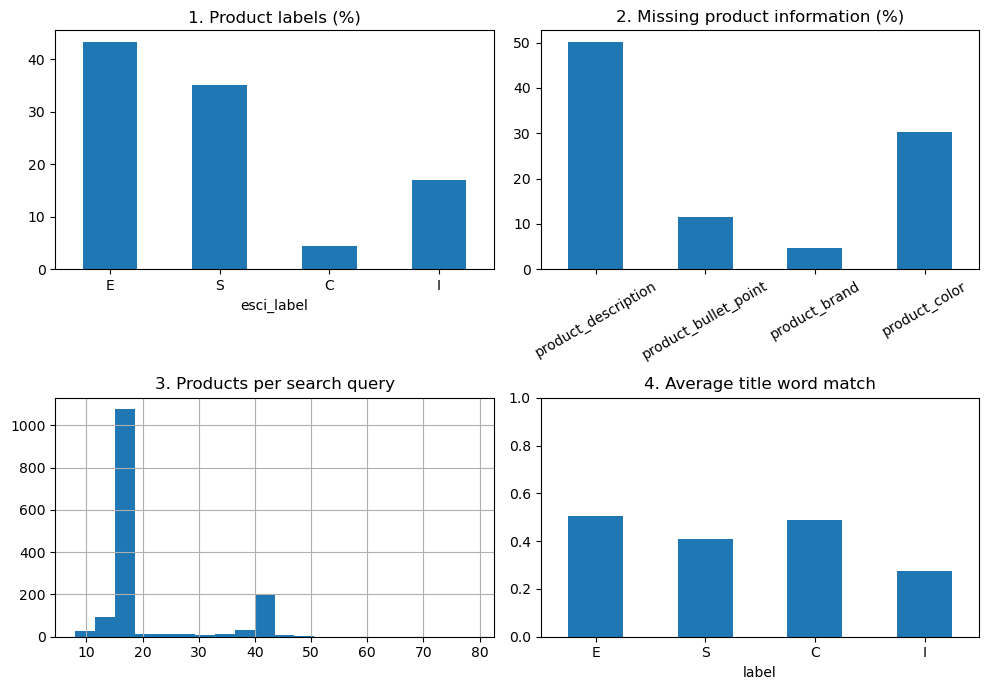

Observation 1: Most common label = E (43.4%). We will check F1-score as well as accuracy because labels are uneven.
Observation 2: 50.2% of rows have no description. We kept them and filled missing text with blanks.
Observation 3: Median products per query = 16. We keep the same query out of both training and test data.
Observation 4: Average title match: E = 0.51, I = 0.28. We test whether this simple feature helps the model.


In [10]:
def clean_text(value):
    # Lowercase text and remove HTML tags/punctuation.
    value = html.unescape(str(value).lower())
    value = re.sub(r"<[^>]+>", " ", value)
    return " ".join(re.findall(r"[a-z0-9]+", value))

def word_match(query, product):
    # Fraction of unique query words also in the product text.
    words = set(query.split())
    return len(words & set(product.split())) / len(words) if words else 0

def make_features(rows):
    # Convert search and product text into five simple numbers.
    query = rows["query"].fillna("").map(clean_text)
    title = rows["product_title"].fillna("").map(clean_text)
    description = rows["product_description"].fillna("").map(clean_text)
    bullets = rows["product_bullet_point"].fillna("").map(clean_text)
    all_text = title + " " + description + " " + bullets
    return pd.DataFrame({
        "title_match": [word_match(q, t) for q, t in zip(query, title)],
        "all_text_match": [word_match(q, t) for q, t in zip(query, all_text)],
        "query_words": query.str.split().str.len(),
        "title_words": title.str.split().str.len(),
        "has_description": (description != "").astype(int),
    }, index=rows.index)

X = make_features(df)
valid = (X["query_words"] > 0) & (X["title_words"] > 0)
before = len(df)
df = df.loc[valid].copy()
X = X.loc[valid].copy()
record("Remove empty query/title after text cleaning", before, len(df))
print("Final number of usable rows:", len(df))
display(pd.DataFrame(cleaning_steps).tail(2))

label_share = df["esci_label"].value_counts(normalize=True).reindex(LABELS, fill_value=0) * 100
missing_pct = (1 - X["has_description"].mean()) * 100
products_per_query = df.groupby("query_id").size()
overlap_by_label = X.assign(label=df["esci_label"]).groupby("label")["title_match"].mean().reindex(LABELS)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
label_share.plot.bar(ax=axes[0, 0], title="1. Product labels (%)", rot=0)
missing_percentages = (df[DETAIL_COLS].eq("").mean() * 100)
missing_percentages.plot.bar(ax=axes[0, 1], title="2. Missing product information (%)")
axes[0, 1].tick_params(axis="x", labelrotation=30)
products_per_query.hist(ax=axes[1, 0], bins=20)
axes[1, 0].set_title("3. Products per search query")
overlap_by_label.plot.bar(ax=axes[1, 1], title="4. Average title word match", rot=0)
axes[1, 1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

print(f"Observation 1: Most common label = {label_share.idxmax()} ({label_share.max():.1f}%). "
      "We will check F1-score as well as accuracy because labels are uneven.")
print(f"Observation 2: {missing_pct:.1f}% of rows have no description. "
      "We kept them and filled missing text with blanks.")
print(f"Observation 3: Median products per query = {products_per_query.median():.0f}. "
      "We keep the same query out of both training and test data.")
print(f"Observation 4: Average title match: E = {overlap_by_label['E']:.2f}, "
      f"I = {overlap_by_label['I']:.2f}. We test whether this simple feature helps the model.")

## 5. Preparing the model 

A model needs numbers rather than raw sentences. Each query–product pair is represented by just five features:

| Feature | Meaning |
|---|---|
| `title_match` | Fraction of query words in the product title |
| `all_text_match` | Fraction found anywhere in the title, description or bullet points |
| `query_words` | Number of words in the search |
| `title_words` | Number of words in the title |
| `has_description` | 1 if description exists, otherwise 0 |

Training teaches the model using examples with known E/S/C/I labels. **Testing** checks predictions on examples it has not been trained on.

We use ESCI's official train/test split if available. We check that no search query appears in both sets to avoid a misleading result. If there is no official split, we make an 80/20 split by query.

In [4]:
if "split" in df.columns and {"train", "test"}.issubset(set(df["split"].unique())):
    train_idx = df.index[df["split"] == "train"]
    test_idx = df.index[df["split"] == "test"]
    print("Using ESCI's official train/test split.")
else:
    splitter = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=RANDOM_STATE)
    positions_train, positions_test = next(splitter.split(X, groups=df["query_id"]))
    train_idx = df.index[positions_train]
    test_idx = df.index[positions_test]
    print("Using a query-level 80/20 split.")

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train = df.loc[train_idx, "esci_label"]
y_test = df.loc[test_idx, "esci_label"]
query_groups = df.loc[train_idx, "query_id"]

train_queries = set(df.loc[train_idx, "query_id"])
test_queries = set(df.loc[test_idx, "query_id"])
assert not (train_queries & test_queries), "Same query in train and test!"
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Queries appearing in both sets:", len(train_queries & test_queries))
display(X_train.head(3))

Using ESCI's official train/test split.
Training rows: 22171 | Test rows: 8126
Queries appearing in both sets: 0


,title_match,all_text_match,query_words,title_words,has_description
40,0.0,0.0,5,18,1
41,0.6,0.6,5,18,1
42,0.2,0.2,5,13,1


## 6. Train and validate Logistic Regression 

We use 3-fold cross-validation. The training queries are divided into three groups; we train on two and check on the third, repeating three times. This shows whether performance is reasonably consistent across different data portions.

The model also scales the five numeric features so they are on comparable scales. `class_weight="balanced"` gives less-common labels more attention. We report macro F1-score because it treats all four labels equally.

In [11]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE)
)

folds = GroupKFold(n_splits=3)
scores = cross_val_score(model, X_train, y_train,
                         cv=folds, groups=query_groups, scoring="f1_macro")
print("Cross-validation F1-scores:", np.round(scores, 3))
print("Average cross-validation F1:", round(scores.mean(), 3))

model.fit(X_train, y_train)
print("Training completed.")

Cross-validation F1-scores: [0.26  0.268 0.291]
Average cross-validation F1: 0.273
Training completed.


### Test the trained model

**Accuracy** is the percentage of correct predictions. **Precision** tells us how many predictions of a class were correct; **recall** tells us how many true examples of a class were found; **F1-score** combines precision and recall. The **confusion matrix** shows which labels the model mixes up.


Test accuracy: 0.353
Test macro F1-score: 0.304

Precision, recall and F1-score for each label:
              precision    recall  f1-score   support

           E       0.56      0.41      0.48      3492
           S       0.47      0.12      0.19      2818
           C       0.08      0.39      0.14       371
           I       0.30      0.66      0.41      1445

    accuracy                           0.35      8126
   macro avg       0.35      0.39      0.30      8126
weighted avg       0.46      0.35      0.35      8126



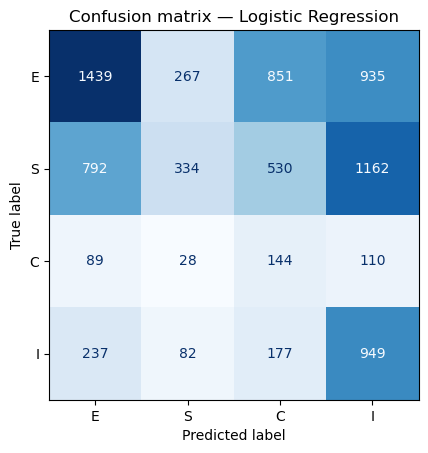

In [12]:
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
macro_f1 = f1_score(y_test, predictions, average="macro", zero_division=0)

print(f"Test accuracy: {accuracy:.3f}")
print(f"Test macro F1-score: {macro_f1:.3f}")
print("\nPrecision, recall and F1-score for each label:")
print(classification_report(y_test, predictions, labels=LABELS, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=LABELS, cmap="Blues", colorbar=False
)
plt.title("Confusion matrix — Logistic Regression")
plt.grid(False)
plt.show()

In [15]:
# Simple baseline: always predict the most common label

most_common = y_train.value_counts().idxmax()

baseline_predictions = [most_common] * len(y_test)

print("Most common label:", most_common)

print("Baseline accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 3))

print("Baseline F1-score:",
      round(f1_score(y_test, baseline_predictions,
                     average="macro", zero_division=0), 3))

Most common label: E
Baseline accuracy: 0.43
Baseline F1-score: 0.15


### Baseline Model Comparison

The majority-class baseline achieved an accuracy of 43.0% and
a macro F1-score of 0.150.

Our Logistic Regression model achieved an accuracy of 35.3%
and a macro F1-score of 0.304.

Although Logistic Regression had lower accuracy, it achieved
a higher macro F1-score, showing better overall performance
across the four relevance categories.

The model still struggled to distinguish Substitute and
Complement products. Further improvements could include
testing other classification algorithms and improving
the input features.

### Small example of how our app could use the model

A student searches for **laptop charger**. These example listings are invented to show the prediction workflow only; they are **not** validation data, and the model is not yet connected to Android.

In [14]:
demo = pd.DataFrame({
    "query": ["laptop charger"] * 4,
    "product_title": ["Laptop USB-C charger", "Universal laptop power adapter",
                      "Laptop carrying sleeve", "Football jersey"],
    "product_description": ["Charges laptops", "Adapter for many models",
                            "Protects your laptop", "Sports clothing"],
    "product_bullet_point": ["", "", "", ""],
})
demo["Predicted relevance"] = model.predict(make_features(demo))
display(demo[["query", "product_title", "Predicted relevance"]])

,query,product_title,Predicted relevance
0,laptop charger,Laptop USB-C charger,E
1,laptop charger,Universal laptop power adapter,C
2,laptop charger,Laptop carrying sleeve,C
3,laptop charger,Football jersey,I
